<a href="https://colab.research.google.com/github/tamusyosus/seminar_report/blob/main/Meteorological_Drought_Prediction_RandomForest.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q imbalanced-learn

In [ ]:
import os, re, json, glob, hashlib, itertools, time, warnings, platform, sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

import sklearn, scipy
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (confusion_matrix, matthews_corrcoef, roc_auc_score,
                             average_precision_score, roc_curve, precision_recall_curve)
import joblib

try:
    from imblearn.over_sampling import SMOTE
    IMBLEARN_OK = True
except ImportError:
    IMBLEARN_OK = False
    print("WARNING: imbalanced-learn not installed -> Experiment D (SMOTE) will be skipped.")

try:
    from IPython.display import display
except ImportError:
    display = print

warnings.filterwarnings("ignore", category=FutureWarning)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

In [ ]:
SEED = 42
np.random.seed(SEED)


MISSING_CODE   = -999
VARIABLES      = ["PRECTOTCORR", "T2M_MAX", "T2M_MIN"]
PRECIP         = "PRECTOTCORR"


SPI_WINDOW     = 30
SPI_THRESHOLD  = -1.0
REF_START      = pd.Timestamp("1981-01-01")
REF_END        = pd.Timestamp("2010-12-31")
PROB_EPS       = 1e-4
ZERO_TOL       = 1e-9
MIN_POSITIVE_OBS = 10

MAX_LAG        = 90
HORIZON        = SPI_WINDOW
PURGE_DAYS     = HORIZON - 1
MODEL_START    = pd.Timestamp("2000-01-01")

TRAIN_FRAC, VAL_FRAC, TEST_FRAC = 0.65, 0.15, 0.20

QUICK_MODE     = False
N_ESTIMATORS   = 300
HP_GRID = [dict(min_samples_leaf=msl, max_depth=md)
           for msl, md in itertools.product([1, 5, 20], [None, 10])]
PERM_REPEATS   = 3
THRESH_GRID    = np.round(np.arange(0.01, 1.00, 0.01), 2)
DEFAULT_THRESHOLD = 0.5
if QUICK_MODE:
    N_ESTIMATORS, HP_GRID, PERM_REPEATS = 60, HP_GRID[:2], 1

OUT_DIR = Path("drought_outputs"); OUT_DIR.mkdir(exist_ok=True)

CHECKS = []
def check(name, condition, detail=""):
    """Assert a methodological condition and record it for the final leakage report."""
    CHECKS.append({"check": name, "passed": bool(condition), "detail": detail})
    assert condition, f"LEAKAGE/INTEGRITY CHECK FAILED: {name} {detail}"
    print(f"  [PASS] {name}" + (f"  ({detail})" if detail else ""))

print("Versions: python", platform.python_version(), "| numpy", np.__version__, "| pandas", pd.__version__,
      "| scipy", scipy.__version__, "| sklearn", sklearn.__version__)

Versions: python 3.13.18 | numpy 2.4.6 | pandas 2.2.3 | scipy 1.16.3 | sklearn 1.6.1


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import glob

files_found = sorted(glob.glob(
    '/content/drive/MyDrive/dataset/POWER_Point_Daily*.csv'
))

if not files_found:
    raise FileNotFoundError("Dataset CSV not found!")

DATA_PATH = files_found[0]

print("Using file:", DATA_PATH)

Using file: /content/drive/MyDrive/dataset/POWER_Point_Daily.csv


In [ ]:
def find_header_row(path, key="YEAR", max_scan=500):
    """Return the 0-based line index of the CSV column-heading row (first line starting with 'YEAR,')."""
    with open(path, "r", encoding="utf-8", errors="replace") as fh:
        for i, line in enumerate(fh):
            if line.strip().upper().startswith(key + ","):
                return i
            if i > max_scan:
                break
    raise ValueError("Could not find a header row beginning with 'YEAR,' - is this a NASA POWER CSV?")

def read_metadata(path, header_row):
    """Parse coordinates / elevation / time standard from the metadata lines above the header."""
    with open(path, "r", encoding="utf-8", errors="replace") as fh:
        meta_lines = [next(fh).rstrip() for _ in range(header_row)]
    text = "\n".join(meta_lines)
    meta = {"raw_metadata": text}
    m = re.search(r"latitude\s+(-?\d+(?:\.\d+)?)\s+longitude\s+(-?\d+(?:\.\d+)?)", text, re.I)
    if m: meta["lat_meta"], meta["lon_meta"] = float(m.group(1)), float(m.group(2))
    m = re.search(r"=\s*([\d.]+)\s*meters", text, re.I)
    if m: meta["elevation_m"] = float(m.group(1))
    m = re.search(r"\bin\s+(LST|UTC)\b", text, re.I)
    if m: meta["time_standard"] = m.group(1).upper()
    m = re.search(r"(\d+)d(\d+)([NS])_(\d+)d(\d+)([EW])", os.path.basename(path))
    if m:
        lat = float(f"{int(m.group(1))}.{m.group(2)}") * (1 if m.group(3) == "N" else -1)
        lon = float(f"{int(m.group(4))}.{m.group(5)}") * (1 if m.group(6) == "E" else -1)
        meta["lat_file"], meta["lon_file"] = lat, lon
    return meta

HEADER_ROW = find_header_row(DATA_PATH)
META = read_metadata(DATA_PATH, HEADER_ROW)
print(f"Header row detected at line index {HEADER_ROW}")
print("\n--- Metadata block of the file ---"); print(META["raw_metadata"])
if "lat_meta" in META and "lat_file" in META:
    same = (abs(META["lat_meta"] - META["lat_file"]) < 0.011) and (abs(META["lon_meta"] - META["lon_file"]) < 0.011)
    print(f"\nCoordinates (metadata) : {META['lat_meta']}, {META['lon_meta']}")
    print(f"Coordinates (filename) : {META['lat_file']}, {META['lon_file']}  -> consistent: {same}")
print("Time standard:", META.get("time_standard", "not found"),
      "| Elevation (MERRA-2 cell mean, m):", META.get("elevation_m", "n/a"))
print("NOTE: no study-region name is assigned here. Confirm the coordinates against your original NASA POWER request.")

Header row detected at line index 11

--- Metadata block of the file ---
-BEGIN HEADER-
NASA/POWER Source Native Resolution Daily Data
Dates (month/day/year): 01/01/1981 through 12/01/2025 in LST
Location: latitude  37.07   longitude 87.33
elevation from MERRA-2: Average for 0.5 x 0.625 degree lat/lon region = 4756.03 meters
The value for missing source data that cannot be computed or is outside of the sources availability range: -999
parameter(s):
T2M_MAX         MERRA-2 Temperature at 2 Meters Maximum (C)
T2M_MIN         MERRA-2 Temperature at 2 Meters Minimum (C)
PRECTOTCORR     MERRA-2 Precipitation Corrected (mm/day)
-END HEADER-
Time standard: LST | Elevation (MERRA-2 cell mean, m): 4756.03
NOTE: no study-region name is assigned here. Confirm the coordinates against your original NASA POWER request.


In [ ]:
raw = pd.read_csv(DATA_PATH, skiprows=HEADER_ROW)
raw.columns = [c.strip() for c in raw.columns]
missing_cols = [c for c in ["YEAR", "DOY"] + VARIABLES if c not in raw.columns]
check("required columns present", not missing_cols, str(missing_cols))

raw[VARIABLES] = raw[VARIABLES].replace(MISSING_CODE, np.nan)
raw["date"] = pd.to_datetime(raw["YEAR"].astype(int).astype(str) + raw["DOY"].astype(int).astype(str).str.zfill(3),
                             format="%Y%j")
raw = raw.sort_values("date").reset_index(drop=True)

n_dup = int(raw["date"].duplicated().sum())
check("no duplicate dates", n_dup == 0, f"{n_dup} duplicates")

full_range = pd.date_range(raw["date"].min(), raw["date"].max(), freq="D")
gaps = full_range.difference(pd.DatetimeIndex(raw["date"]))
check("daily series is continuous (no missing calendar days)", len(gaps) == 0, f"{len(gaps)} missing days")

df = raw.set_index("date")[VARIABLES].astype(float)
n_nan = df.isna().sum()
check("no missing values after -999 -> NaN", int(n_nan.sum()) == 0, n_nan.to_dict())
check("precipitation is non-negative", bool((df[PRECIP] >= 0).all()))
check("data cover the reference start", df.index.min() <= REF_START, f"first date {df.index.min().date()}")
check("enough history before first prediction date for 90 lags",
      df.index.min() <= MODEL_START - pd.Timedelta(days=MAX_LAG), f"first date {df.index.min().date()}")

print(f"\nRows: {len(df):,} | {df.index.min().date()} -> {df.index.max().date()}")
display(df.describe().round(3))
print(f"Share of days with zero precipitation: {(df[PRECIP] == 0).mean():.1%}")

  [PASS] required columns present  ([])
  [PASS] no duplicate dates  (0 duplicates)
  [PASS] daily series is continuous (no missing calendar days)  (0 missing days)
  [PASS] no missing values after -999 -> NaN  ({'PRECTOTCORR': 0, 'T2M_MAX': 0, 'T2M_MIN': 0})
  [PASS] precipitation is non-negative
  [PASS] data cover the reference start  (first date 1981-01-01)
  [PASS] enough history before first prediction date for 90 lags  (first date 1981-01-01)

Rows: 16,406 | 1981-01-01 -> 2025-12-01


,PRECTOTCORR,T2M_MAX,T2M_MIN
count,16406.000,16406.000,16406.000
mean,0.115,0.931,-12.145
std,0.884,9.369,8.403
min,0.000,-22.750,-33.240
25%,0.000,-6.990,-19.710
50%,0.000,0.700,-10.680
75%,0.000,9.030,-5.130
max,33.060,24.050,5.500


Share of days with zero precipitation: 77.5%


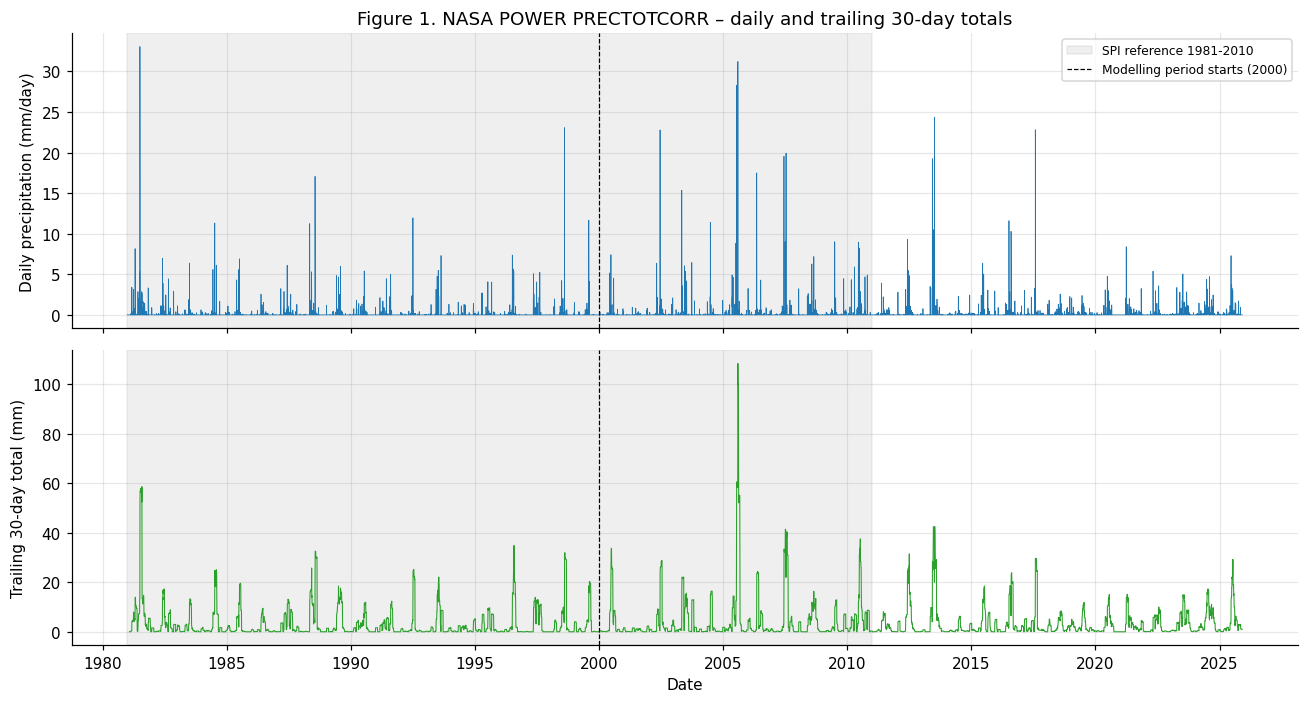

In [ ]:
fig, ax = plt.subplots(2, 1, figsize=(12, 6.5), sharex=True)
ax[0].plot(df.index, df[PRECIP], lw=0.5, color="tab:blue")
ax[0].set_ylabel("Daily precipitation (mm/day)")
ax[0].set_title("Figure 1. NASA POWER PRECTOTCORR – daily and trailing 30-day totals")
trail30 = df[PRECIP].rolling(SPI_WINDOW, min_periods=SPI_WINDOW).sum()
ax[1].plot(trail30.index, trail30, lw=0.7, color="tab:green")
ax[1].set_ylabel("Trailing 30-day total (mm)")
for a in ax:
    a.axvspan(REF_START, REF_END, color="grey", alpha=0.12, label="SPI reference 1981-2010")
    a.axvline(MODEL_START, color="k", ls="--", lw=0.8, label="Modelling period starts (2000)")
ax[0].legend(loc="upper right", fontsize=8)
ax[1].set_xlabel("Date")
plt.tight_layout(); plt.savefig(OUT_DIR / "fig01_precipitation_timeseries.png", dpi=150); plt.show()

In [ ]:
def trailing_sum(precip, window=SPI_WINDOW):
    s = precip.rolling(window, min_periods=window).sum().round(6)
    s[s.abs() < ZERO_TOL] = 0.0
    return s

def fit_spi_parameters(totals, ref_start=REF_START, ref_end=REF_END):
    ref = totals.loc[ref_start:ref_end].dropna()
    assert ref.index.min() >= ref_start and ref.index.max() <= ref_end
    params, rows = {}, []
    for m in range(1, 13):
        x = ref[ref.index.month == m].to_numpy()
        pos = x[x > ZERO_TOL]
        q0 = float((x <= ZERO_TOL).mean()) if x.size else np.nan
        rec = dict(month=m, n_ref=int(x.size), n_positive=int(pos.size), q0=q0, shape=np.nan, scale=np.nan,
                   method="no_reference_data", sorted_ref=None)
        if x.size == 0:
            pass
        elif pos.size == 0:
            rec["method"] = "all_zero"
        else:
            ok = False
            if pos.size >= MIN_POSITIVE_OBS and np.ptp(pos) > 0:
                try:
                    with warnings.catch_warnings():
                        warnings.simplefilter("ignore")
                        a, _, sc = stats.gamma.fit(pos, floc=0)
                    ok = bool(np.isfinite(a) and np.isfinite(sc) and a > 0 and sc > 0)
                except Exception:
                    ok = False
            if ok:
                rec.update(method="gamma", shape=float(a), scale=float(sc))
            else:
                rec.update(method="empirical_fallback", sorted_ref=np.sort(x))
        params[m] = rec
        rows.append({k: v for k, v in rec.items() if k != "sorted_ref"})
    table = pd.DataFrame(rows).set_index("month")
    table["ref_first_window_end"] = ref.index.min()
    table["ref_last_window_end"] = ref.index.max()
    return params, table

def apply_spi(totals, months, params):
    """Convert 30-day totals into SPI using FIXED parameters. `months` = calendar month of each window's end date."""
    totals, months = np.asarray(totals, float), np.asarray(months)
    out = np.full(totals.shape, np.nan)
    for m in range(1, 13):
        sel = (months == m) & ~np.isnan(totals)
        if not sel.any():
            continue
        p, x = params[m], totals[sel]
        if p["method"] == "gamma":
            prob = p["q0"] + (1 - p["q0"]) * stats.gamma.cdf(x, p["shape"], loc=0, scale=p["scale"])
            prob = np.where(x <= ZERO_TOL, p["q0"], prob)
        elif p["method"] == "all_zero":
            prob = np.ones_like(x)
        elif p["method"] == "empirical_fallback":
            ref = p["sorted_ref"]
            prob = np.searchsorted(ref, x, side="right") / (len(ref) + 1.0)
        else:
            continue
        out[sel] = stats.norm.ppf(np.clip(prob, PROB_EPS, 1 - PROB_EPS))
    return out

totals_trailing = trailing_sum(df[PRECIP])
SPI_PARAMS, SPI_TABLE = fit_spi_parameters(totals_trailing)

phi_thr = stats.norm.cdf(SPI_THRESHOLD)
SPI_TABLE["drought_possible"] = (SPI_TABLE["q0"] < phi_thr)
print(f"Reference windows end between {SPI_TABLE['ref_first_window_end'].iloc[0].date()} and {SPI_TABLE['ref_last_window_end'].iloc[0].date()}")
print(f"Phi({SPI_THRESHOLD}) = {phi_thr:.4f}: months with zero-rain probability q0 above this cannot be classed as drought.")
display(SPI_TABLE.drop(columns=["ref_first_window_end", "ref_last_window_end"]).round(4))

Reference windows end between 1981-01-30 and 2010-12-31
Phi(-1.0) = 0.1587: months with zero-rain probability q0 above this cannot be classed as drought.


,n_ref,n_positive,q0,shape,scale,method,drought_possible
month,,,,,,,
1,901,757,0.1598,0.7412,1.6502,gamma,False
2,847,645,0.2385,0.5994,0.9701,gamma,False
3,930,811,0.1280,0.6047,1.5802,gamma,True
4,900,781,0.1322,0.4746,2.7198,gamma,True
5,930,852,0.0839,0.5030,8.5236,gamma,True
6,900,889,0.0122,0.7991,8.0595,gamma,True
7,930,930,0.0000,1.1485,12.2541,gamma,True
8,930,930,0.0000,0.6439,14.9243,gamma,True
9,900,850,0.0556,0.5188,5.4752,gamma,True


In [ ]:
rng = np.random.default_rng(SEED)
precip_perturbed = df[PRECIP].copy()
after = precip_perturbed.index > REF_END
precip_perturbed[after] = np.round(rng.gamma(0.5, 8.0, after.sum()), 2)
params_pert, _ = fit_spi_parameters(trailing_sum(precip_perturbed))
same = all((params_pert[m]["method"] == SPI_PARAMS[m]["method"]) and
           np.allclose([params_pert[m]["q0"], params_pert[m]["shape"], params_pert[m]["scale"]],
                       [SPI_PARAMS[m]["q0"], SPI_PARAMS[m]["shape"], SPI_PARAMS[m]["scale"]], equal_nan=True)
           for m in range(1, 13))
check("SPI parameters unchanged when ALL post-2010 precipitation is replaced with random values", same)
check("all SPI fitting windows end within 1981-2010",
      SPI_TABLE["ref_last_window_end"].iloc[0] <= REF_END and SPI_TABLE["ref_first_window_end"].iloc[0] >= REF_START)
check("no 2011-2025 observation (incl. 2021-2025 test years) enters SPI fitting",
      SPI_TABLE["ref_last_window_end"].iloc[0] <= REF_END < pd.Timestamp("2021-01-01"))

  [PASS] SPI parameters unchanged when ALL post-2010 precipitation is replaced with random values
  [PASS] all SPI fitting windows end within 1981-2010
  [PASS] no 2011-2025 observation (incl. 2021-2025 test years) enters SPI fitting


In [ ]:
def compute_spi_future(precip, params):
    """spi_future[t] = SPI of precip[t .. t+29]; built as trailing SPI (window ending t+29) shifted back by 29 rows."""
    tot = trailing_sum(precip)
    spi_tr = pd.Series(apply_spi(tot.to_numpy(), tot.index.month.to_numpy(), params), index=tot.index)
    return spi_tr, spi_tr.shift(-(SPI_WINDOW - 1))

spi_trailing, spi_future = compute_spi_future(df[PRECIP], SPI_PARAMS)
drought_class = (spi_future <= SPI_THRESHOLD).astype(float).where(spi_future.notna())
drought_class.name = "drought_class"
print(f"Labelled dates: {drought_class.notna().sum():,}   (unlabelled final {SPI_WINDOW-1} dates: "
      f"{df.index[-(SPI_WINDOW-1)].date()} -> {df.index[-1].date()})")

Labelled dates: 16,377   (unlabelled final 29 dates: 2025-11-03 -> 2025-12-01)


In [ ]:
P = df[PRECIP].to_numpy()
cs = np.concatenate([[0.0], np.cumsum(P)])
fwd_total = np.round(cs[SPI_WINDOW:] - cs[:-SPI_WINDOW], 6)
fwd_total[np.abs(fwd_total) < ZERO_TOL] = 0.0
end_months = df.index[SPI_WINDOW - 1:].month.to_numpy()
spi_check = apply_spi(fwd_total, end_months, SPI_PARAMS)
n_valid = len(fwd_total)
check("Test 1: spi_future[t] == SPI(sum of precip[t..t+29]) for every date (cumsum recomputation)",
      np.allclose(spi_future.to_numpy()[:n_valid], spi_check, atol=1e-9, equal_nan=True))
check("last 29 dates correctly unlabelled", bool(spi_future.iloc[n_valid:].isna().all()) and len(spi_future) - n_valid == SPI_WINDOW - 1)


sample_dates = [pd.Timestamp("2000-01-01"), pd.Timestamp("2010-12-31"), pd.Timestamp("2021-06-15"),
                df.index[n_valid - 1]] + list(pd.DatetimeIndex(rng.choice(df.loc["2000":].index[:-(SPI_WINDOW - 1)], 4, replace=False)))
rows = []
for t in sample_dates:
    t_end = t + pd.Timedelta(days=SPI_WINDOW - 1)
    window = df.loc[t:t_end, PRECIP]
    tot = round(float(window.sum()), 6)
    spi_manual = apply_spi([tot], [t_end.month], SPI_PARAMS)[0]
    rows.append(dict(pred_date=t.date(), target_window_start=t.date(), target_window_end=t_end.date(),
                     n_days=len(window), window_total_mm=tot, SPI_manual=round(spi_manual, 4),
                     spi_future_stored=round(float(spi_future.loc[t]), 4)))
    assert len(window) == SPI_WINDOW and abs(spi_manual - spi_future.loc[t]) < 1e-9
display(pd.DataFrame(rows))
check("Test 2: label-sliced window t..t+29 has exactly 30 days and reproduces stored SPI for all sample dates", True)


t0 = pd.Timestamp("2005-07-10")
base = spi_future.loc[t0]
def spi_future_after_bump(day):
    p2 = df[PRECIP].copy(); p2.loc[day] += 200.0
    return compute_spi_future(p2, SPI_PARAMS)[1].loc[t0]
inside  = [spi_future_after_bump(t0 + pd.Timedelta(days=k)) for k in (0, 15, 29)]
before  = spi_future_after_bump(t0 - pd.Timedelta(days=1))
after30 = spi_future_after_bump(t0 + pd.Timedelta(days=30))
check("Test 3a: rainfall on day t, t+15 and t+29 DOES change target(t)", all(abs(v - base) > 1e-6 for v in inside))
check("Test 3b: rainfall on day t-1 does NOT change target(t)", abs(before - base) < 1e-12)
check("Test 3c: rainfall on day t+30 does NOT change target(t)", abs(after30 - base) < 1e-12)

  [PASS] Test 1: spi_future[t] == SPI(sum of precip[t..t+29]) for every date (cumsum recomputation)
  [PASS] last 29 dates correctly unlabelled


,pred_date,target_window_start,target_window_end,n_days,window_total_mm,SPI_manual,spi_future_stored
0,2000-01-01,2000-01-01,2000-01-30,30,0.36,-0.1751,-0.1751
1,2010-12-31,2010-12-31,2011-01-29,30,0.00,-0.9952,-0.9952
2,2021-06-15,2021-06-15,2021-07-14,30,2.10,-1.2141,-1.2141
3,2025-11-02,2025-11-02,2025-12-01,30,0.97,0.8322,0.8322
4,2022-01-26,2022-01-26,2022-02-24,30,0.10,-0.1291,-0.1291
5,2007-07-08,2007-07-08,2007-08-06,30,31.24,1.5530,1.5530
6,2017-02-28,2017-02-28,2017-03-29,30,0.28,-0.1286,-0.1286
7,2005-04-07,2005-04-07,2005-05-06,30,1.49,-0.0253,-0.0253


  [PASS] Test 2: label-sliced window t..t+29 has exactly 30 days and reproduces stored SPI for all sample dates
  [PASS] Test 3a: rainfall on day t, t+15 and t+29 DOES change target(t)
  [PASS] Test 3b: rainfall on day t-1 does NOT change target(t)
  [PASS] Test 3c: rainfall on day t+30 does NOT change target(t)


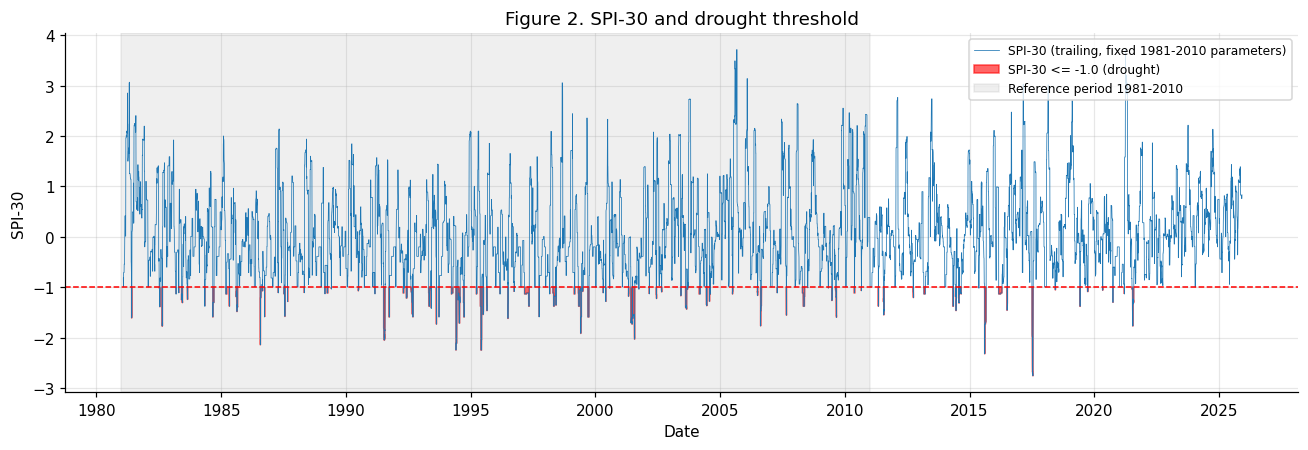

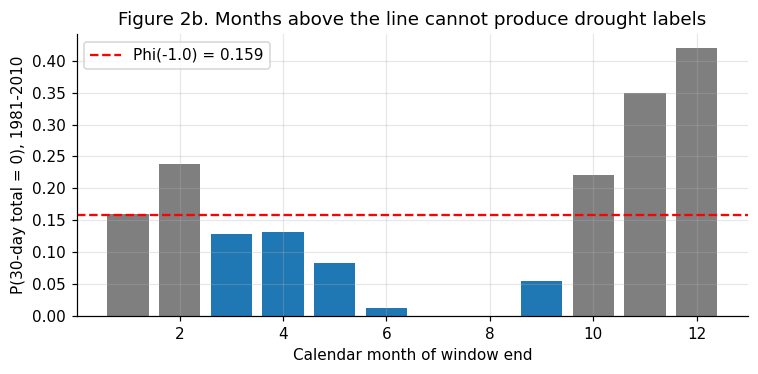

In [ ]:
fig, ax = plt.subplots(figsize=(12, 4.2))
s = spi_trailing.dropna()
ax.plot(s.index, s, lw=0.5, color="tab:blue", label="SPI-30 (trailing, fixed 1981-2010 parameters)")
ax.fill_between(s.index, s, SPI_THRESHOLD, where=(s <= SPI_THRESHOLD), color="red", alpha=0.6, label="SPI-30 <= -1.0 (drought)")
ax.axhline(SPI_THRESHOLD, color="red", ls="--", lw=1)
ax.axvspan(REF_START, REF_END, color="grey", alpha=0.12, label="Reference period 1981-2010")
ax.set(xlabel="Date", ylabel="SPI-30", title="Figure 2. SPI-30 and drought threshold")
ax.legend(loc="upper right", fontsize=8); plt.tight_layout()
plt.savefig(OUT_DIR / "fig02_spi30_timeseries.png", dpi=150); plt.show()


fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(SPI_TABLE.index, SPI_TABLE["q0"], color=np.where(SPI_TABLE["drought_possible"], "tab:blue", "tab:grey"))
ax.axhline(phi_thr, color="red", ls="--", label=f"Phi({SPI_THRESHOLD}) = {phi_thr:.3f}")
ax.set(xlabel="Calendar month of window end", ylabel="P(30-day total = 0), 1981-2010",
       title="Figure 2b. Months above the line cannot produce drought labels"); ax.legend()
plt.tight_layout(); plt.savefig(OUT_DIR / "fig02b_zero_rain_probability.png", dpi=150); plt.show()

In [ ]:
def build_lag_features(frame, variables=VARIABLES, max_lag=MAX_LAG):
    cols = {f"{v}_lag{k}": frame[v].shift(k) for v in variables for k in range(1, max_lag + 1)}
    return pd.DataFrame(cols, index=frame.index)

X_full = build_lag_features(df)
FEATURES = list(X_full.columns)
check("exactly 270 predictor features", len(FEATURES) == 270 and len(set(FEATURES)) == 270, f"{len(FEATURES)} features")
check("feature names follow <VAR>_lag1..lag90 for the three variables",
      FEATURES == [f"{v}_lag{k}" for v in VARIABLES for k in range(1, MAX_LAG + 1)])

  [PASS] exactly 270 predictor features  (270 features)
  [PASS] feature names follow <VAR>_lag1..lag90 for the three variables


In [ ]:
pred_mask = (df.index >= MODEL_START) & drought_class.notna().to_numpy()
X_all = X_full.loc[pred_mask].astype("float32")
y_all = drought_class.loc[pred_mask].astype(int)
dates = X_all.index
check("no NaN in any of the 270 predictors for any prediction date", not X_all.isna().any().any())
check("rows are strictly increasing in time (no shuffling)", bool(dates.is_monotonic_increasing and dates.is_unique))
print(f"Prediction dates: {dates.min().date()} -> {dates.max().date()}  (n = {len(dates):,})")

n = len(dates)
n_train_nom, n_val_nom = int(np.floor(TRAIN_FRAC * n)), int(np.floor(VAL_FRAC * n))
VAL_START  = dates[n_train_nom]
TEST_START = dates[n_train_nom + n_val_nom]
purge = pd.Timedelta(days=PURGE_DAYS)

train_mask = (dates + purge) < VAL_START
val_mask   = (dates >= VAL_START) & ((dates + purge) < TEST_START)
test_mask  = dates >= TEST_START

X_train, y_train = X_all[train_mask], y_all[train_mask]
X_val,   y_val   = X_all[val_mask],   y_all[val_mask]
purged_tv = dates[(dates < VAL_START) & ~train_mask]
purged_vt = dates[(dates >= VAL_START) & (dates < TEST_START) & ~val_mask]

print(f"Train      : {X_train.index.min().date()} -> {X_train.index.max().date()}  n={len(X_train):,}")
print(f"Purge T|V  : {purged_tv.min().date()} -> {purged_tv.max().date()}  n={len(purged_tv)}")
print(f"Validation : {X_val.index.min().date()} -> {X_val.index.max().date()}  n={len(X_val):,}")
print(f"Purge V|T  : {purged_vt.min().date()} -> {purged_vt.max().date()}  n={len(purged_vt)}")
print(f"Test       : {dates[test_mask].min().date()} -> {dates[test_mask].max().date()}  n={test_mask.sum():,}")

  [PASS] no NaN in any of the 270 predictors for any prediction date
  [PASS] rows are strictly increasing in time (no shuffling)
Prediction dates: 2000-01-01 -> 2025-11-02  (n = 9,438)
Train      : 2000-01-01 -> 2016-09-17  n=6,105
Purge T|V  : 2016-09-18 -> 2016-10-16  n=29
Validation : 2016-10-17 -> 2020-08-02  n=1,386
Purge V|T  : 2020-08-03 -> 2020-08-31  n=29
Test       : 2020-09-01 -> 2025-11-02  n=1,889


In [ ]:
class SealedTestSet:
    def __init__(self, X, y):
        self._X, self._y, self._sealed = X, y, True
        self.dates = X.index
        self.blocked_attempts, self.frozen_hash_at_unseal = 0, None
    def counts(self):                                  # descriptive only
        return {"n": len(self._y), "drought": int(self._y.sum()), "non_drought": int((self._y == 0).sum())}
    def unseal(self, frozen_hash):
        self._sealed, self.frozen_hash_at_unseal = False, frozen_hash
    def _get(self, obj):
        if self._sealed:
            self.blocked_attempts += 1
            raise PermissionError("Test set is sealed: finish model + threshold selection and freeze them first.")
        return obj
    @property
    def X(self): return self._get(self._X)
    @property
    def y(self): return self._get(self._y)

TEST = SealedTestSet(X_all[test_mask], y_all[test_mask])


tr_last_target_end  = X_train.index.max() + purge
val_last_target_end = X_val.index.max() + purge
check("partitions are chronological: train < validation < test", X_train.index.max() < X_val.index.min() and X_val.index.max() < TEST.dates.min())
check("partitions are disjoint", len(set(X_train.index) & set(X_val.index)) == 0 and len(set(X_val.index) & set(TEST.dates)) == 0)
check("last TRAIN target window (t..t+29) ends before the validation period starts", tr_last_target_end < X_val.index.min(),
      f"{tr_last_target_end.date()} < {X_val.index.min().date()}")
check("last VALIDATION target window ends before the test period starts", val_last_target_end < TEST.dates.min(),
      f"{val_last_target_end.date()} < {TEST.dates.min().date()}")
check("exactly 29 prediction dates purged at the train|validation boundary", len(purged_tv) == PURGE_DAYS, f"{len(purged_tv)}")
check("exactly 29 prediction dates purged at the validation|test boundary", len(purged_vt) == PURGE_DAYS, f"{len(purged_vt)}")
check("purge is exactly as long as needed: the earliest purged training date's target window DOES reach the validation block",
      (purged_tv.min() + purge) >= X_val.index.min())
check("predictor history of validation/test rows is NOT truncated (first val row still has its full 90-day history)",
      bool(X_val.iloc[0].notna().all()) and bool(TEST._X.iloc[0].notna().all()))
check("target windows of training rows never contain a validation/test prediction date",
      not ((X_train.index + purge) >= X_val.index.min()).any())
check("SPI fitting period (<=2010-12-31) ends before the validation block", REF_END < X_val.index.min(), f"validation starts {X_val.index.min().date()}")
check("SPI fitting period ends before the test block", REF_END < TEST.dates.min())


def episodes(y):
    v = np.asarray(y).astype(int); return int(((v[1:] == 1) & (v[:-1] == 0)).sum() + (v[0] == 1)) if len(v) else 0
part_rows = []
for name, yy, idx in [("Training", y_train, X_train.index), ("Validation", y_val, X_val.index), ("Test", TEST._y, TEST.dates)]:
    nd = int(yy.sum()); nn = int((yy == 0).sum())
    part_rows.append(dict(partition=name, start=idx.min().date(), end=idx.max().date(), n=len(yy), non_drought=nn,
                          drought=nd, drought_prevalence=nd / len(yy), drought_episodes=episodes(yy)))
PARTITION_TABLE = pd.DataFrame(part_rows).set_index("partition")
display(PARTITION_TABLE.round(4))
print("`drought_episodes` = number of separate runs of consecutive drought-labelled days. Consecutive daily labels are strongly "
      "autocorrelated (overlapping 30-day windows), so the number of INDEPENDENT drought events is far smaller than the number of drought days.")
print(f"Reference only (from the 1981-2010 SPI fit): {SPI_TABLE['drought_possible'].sum()} of 12 calendar months can produce drought labels.")

  [PASS] partitions are chronological: train < validation < test
  [PASS] partitions are disjoint
  [PASS] last TRAIN target window (t..t+29) ends before the validation period starts  (2016-10-16 < 2016-10-17)
  [PASS] last VALIDATION target window ends before the test period starts  (2020-08-31 < 2020-09-01)
  [PASS] exactly 29 prediction dates purged at the train|validation boundary  (29)
  [PASS] exactly 29 prediction dates purged at the validation|test boundary  (29)
  [PASS] purge is exactly as long as needed: the earliest purged training date's target window DOES reach the validation block
  [PASS] predictor history of validation/test rows is NOT truncated (first val row still has its full 90-day history)
  [PASS] target windows of training rows never contain a validation/test prediction date
  [PASS] SPI fitting period (<=2010-12-31) ends before the validation block  (validation starts 2016-10-17)
  [PASS] SPI fitting period ends before the test block


,start,end,n,non_drought,drought,drought_prevalence,drought_episodes
partition,,,,,,,
Training,2000-01-01,2016-09-17,6105,5670,435,0.0713,43
Validation,2016-10-17,2020-08-02,1386,1343,43,0.0310,5
Test,2020-09-01,2025-11-02,1889,1857,32,0.0169,3


`drought_episodes` = number of separate runs of consecutive drought-labelled days. Consecutive daily labels are strongly autocorrelated (overlapping 30-day windows), so the number of INDEPENDENT drought events is far smaller than the number of drought days.
Reference only (from the 1981-2010 SPI fit): 7 of 12 calendar months can produce drought labels.


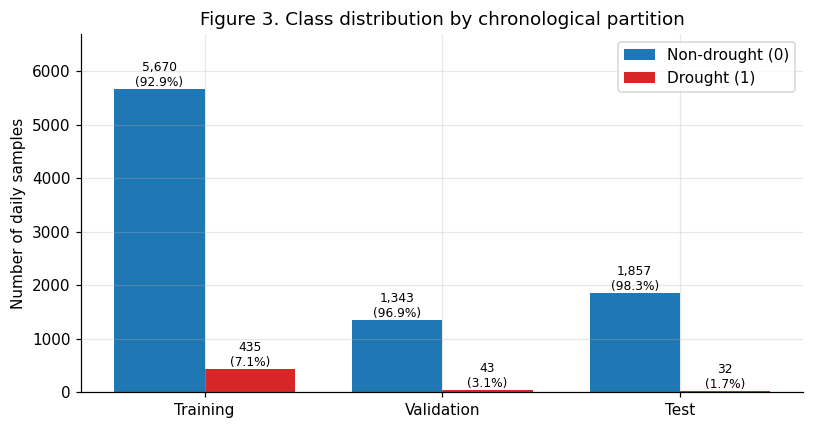

In [ ]:
fig, ax = plt.subplots(figsize=(7.5, 4))
parts = ["Training", "Validation", "Test"]; w = 0.38; xs = np.arange(3)
nd = PARTITION_TABLE.loc[parts, "non_drought"].to_numpy(); dr = PARTITION_TABLE.loc[parts, "drought"].to_numpy()
b1 = ax.bar(xs - w/2, nd, w, label="Non-drought (0)", color="tab:blue")
b2 = ax.bar(xs + w/2, dr, w, label="Drought (1)", color="tab:red")
for bars, vals in ((b1, nd), (b2, dr)):
    for b, v, tot in zip(bars, vals, nd + dr):
        ax.text(b.get_x() + b.get_width()/2, b.get_height(), f"{v:,}\n({v/tot:.1%})", ha="center", va="bottom", fontsize=8)
ax.set_xticks(xs); ax.set_xticklabels(parts); ax.set_ylabel("Number of daily samples")
ax.set_title("Figure 3. Class distribution by chronological partition"); ax.legend(); ax.set_ylim(0, max(nd) * 1.18)
plt.tight_layout(); plt.savefig(OUT_DIR / "fig03_class_distribution.png", dpi=150); plt.show()

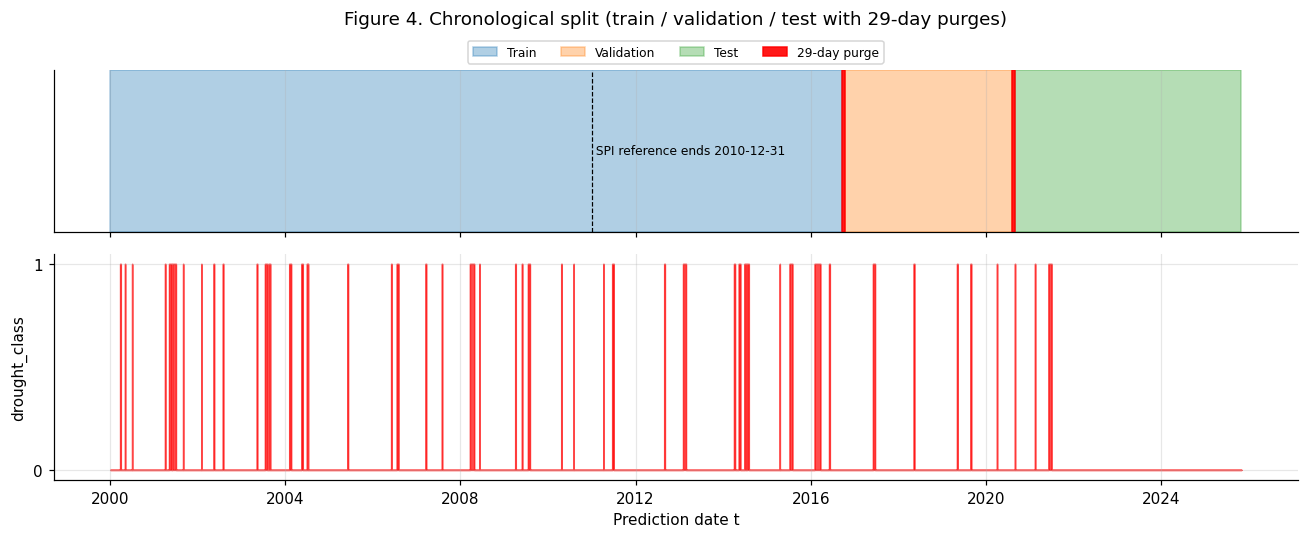

In [ ]:
fig, ax = plt.subplots(2, 1, figsize=(12, 5), sharex=True, gridspec_kw={"height_ratios": [1, 1.4]})
for lo, hi, col, lab in [(X_train.index.min(), X_train.index.max(), "tab:blue", "Train"),
                         (X_val.index.min(), X_val.index.max(), "tab:orange", "Validation"),
                         (TEST.dates.min(), TEST.dates.max(), "tab:green", "Test")]:
    ax[0].axvspan(lo, hi, color=col, alpha=0.35, label=lab)
for lo, hi in [(purged_tv.min(), purged_tv.max()), (purged_vt.min(), purged_vt.max())]:
    ax[0].axvspan(lo, hi, color="red", alpha=0.9, label="29-day purge" if lo == purged_tv.min() else None)
ax[0].axvline(REF_END, color="k", ls="--", lw=0.8); ax[0].text(REF_END, 0.5, " SPI reference ends 2010-12-31", va="center", fontsize=8)
ax[0].set_yticks([]); ax[0].legend(ncol=4, loc="lower center", fontsize=8, bbox_to_anchor=(0.5, 1.0))
ax[0].set_title("Figure 4. Chronological split (train / validation / test with 29-day purges)", pad=30)
ax[1].fill_between(dates, y_all.to_numpy(), step="mid", color="red", alpha=0.7)
ax[1].set(ylabel="drought_class", xlabel="Prediction date t", yticks=[0, 1])
plt.tight_layout(); plt.savefig(OUT_DIR / "fig04_chronological_split.png", dpi=150); plt.show()

In [ ]:
def fbeta(p, r, beta):
    d = beta**2 * p + r
    return (1 + beta**2) * p * r / d if d > 0 else 0.0

def compute_metrics(y_true, y_pred, y_score):
    y_true, y_pred = np.asarray(y_true).astype(int), np.asarray(y_pred).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    pos, neg = tp + fn, tn + fp
    prec = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    rec  = tp / pos if pos > 0 else np.nan
    spec = tn / neg if neg > 0 else np.nan
    has_both = (pos > 0) and (neg > 0)
    return {"accuracy": (tp + tn) / len(y_true), "precision_drought": prec, "recall_drought": rec,
            "f1": fbeta(prec, rec, 1) if pos > 0 else np.nan, "f2": fbeta(prec, rec, 2) if pos > 0 else np.nan,
            "specificity": spec, "balanced_accuracy": np.nanmean([rec, spec]) if has_both else np.nan,
            "roc_auc": roc_auc_score(y_true, y_score) if has_both else np.nan,
            "pr_auc_avg_precision": average_precision_score(y_true, y_score) if pos > 0 else np.nan,
            "mcc": matthews_corrcoef(y_true, y_pred), "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp),
            "n": len(y_true), "n_drought": int(pos), "prevalence": pos / len(y_true),
            "predicted_drought_rate": (tp + fp) / len(y_true)}

def threshold_sweep(y_true, proba, grid=THRESH_GRID):
    """Vectorised precision / recall / F2 for every candidate threshold (used on VALIDATION data only)."""
    y = np.asarray(y_true).astype(bool)[:, None]; pred = np.asarray(proba)[:, None] >= grid[None, :]
    tp = (pred & y).sum(0); fp = (pred & ~y).sum(0); fn = (~pred & y).sum(0)
    prec = np.divide(tp, tp + fp, out=np.zeros(len(grid)), where=(tp + fp) > 0)
    rec  = np.divide(tp, tp + fn, out=np.zeros(len(grid)), where=(tp + fn) > 0)
    f2 = np.divide(5 * prec * rec, 4 * prec + rec, out=np.zeros(len(grid)), where=(4 * prec + rec) > 0)
    return pd.DataFrame({"threshold": grid, "precision": prec, "recall": rec, "f2": f2, "predicted_rate": pred.mean(0)})

def select_threshold(y_val_, proba_val):
    """Pick the F2-maximising threshold on validation; ties -> the HIGHEST tied threshold (fewest false alarms).
    Falls back to 0.5 if no threshold achieves F2 > 0 (e.g. no validation signal)."""
    sw = threshold_sweep(y_val_, proba_val)
    best = sw["f2"].max()
    if best <= 0:
        return DEFAULT_THRESHOLD, sw, "fallback_default_no_valid_threshold"
    return float(sw.loc[np.isclose(sw["f2"], best), "threshold"].max()), sw, "f2_max_on_validation"

In [ ]:
SMOTE_LOG = []

def smote_train_only(X_tr, y_tr):
    """Apply SMOTE to the TRAINING arrays only. Returns (X_res, y_res, status)."""
    if not IMBLEARN_OK:
        return None, None, "skipped: imbalanced-learn not installed"
    n_min = int(y_tr.sum())
    if n_min < 2:
        return None, None, f"skipped: only {n_min} minority sample(s) in training"
    k = max(1, min(5, n_min - 1))                          # k_neighbors must be < number of minority samples
    try:
        Xr, yr = SMOTE(random_state=SEED, k_neighbors=k).fit_resample(X_tr, y_tr)
    except Exception as e:                                 # e.g. neighbours cannot be found
        return None, None, f"skipped: SMOTE failed ({type(e).__name__}: {e})"
    SMOTE_LOG.append({"rows_in": len(X_tr), "rows_out": len(Xr), "cols": X_tr.shape[1], "k_neighbors": k})
    return Xr, yr, f"ok (k_neighbors={k})"

EXPERIMENTS = {
    "A_standard":           dict(label="A: Standard RF",             class_weight=None,                 smote=False),
    "B_balanced_subsample": dict(label="B: balanced_subsample",      class_weight="balanced_subsample", smote=False),
    "C_balanced":           dict(label="C: balanced",                class_weight="balanced",           smote=False),
    "D_smote":              dict(label="D: SMOTE (train only)",      class_weight=None,                 smote=True),
}

def make_rf(cfg, class_weight):
    return RandomForestClassifier(n_estimators=N_ESTIMATORS, random_state=SEED, n_jobs=-1,
                                  class_weight=class_weight, **cfg)

RESULTS = {}
SEARCH_ROWS = []
t_start_all = time.time()
for key, spec in EXPERIMENTS.items():
    print(f"\n=== {spec['label']} ===")
    Xtr, ytr, smote_status = X_train, y_train, "n/a"
    if spec["smote"]:
        Xr, yr, smote_status = smote_train_only(X_train, y_train)
        print("  SMOTE:", smote_status)
        if Xr is None:
            RESULTS[key] = dict(status=smote_status, model=None); continue

        Xr_np = Xr.to_numpy() if hasattr(Xr, "to_numpy") else np.asarray(Xr)
        n0 = len(X_train)
        check("SMOTE input had exactly the training rows (validation/test never passed in)",
              SMOTE_LOG[-1]["rows_in"] == len(X_train) and SMOTE_LOG[-1]["cols"] == len(FEATURES))
        check("SMOTE output keeps the original training rows unchanged", np.allclose(Xr_np[:n0], X_train.to_numpy(), equal_nan=False))
        syn = Xr_np[n0:]
        lo, hi = X_train.to_numpy().min(0), X_train.to_numpy().max(0)
        check("synthetic SMOTE rows lie within the training feature range (no outside information)",
              bool((syn >= lo - 1e-3).all() and (syn <= hi + 1e-3).all()))
        print(f"  training rows {len(X_train):,} -> {len(Xr_np):,}; classes {dict(pd.Series(np.asarray(yr)).value_counts().sort_index())}")
        Xtr, ytr = Xr, yr
    best = None
    for i, cfg in enumerate(HP_GRID):
        t0 = time.time()
        rf = make_rf(cfg, spec["class_weight"]).fit(Xtr, ytr)
        pv = rf.predict_proba(X_val)[:, 1]                                   # validation probabilities
        ap = average_precision_score(y_val, pv) if y_val.sum() > 0 else np.nan
        auc = roc_auc_score(y_val, pv) if 0 < y_val.sum() < len(y_val) else np.nan
        SEARCH_ROWS.append(dict(experiment=spec["label"], **cfg, val_avg_precision=ap, val_roc_auc=auc, fit_seconds=time.time() - t0))
        score = ap if np.isfinite(ap) else -np.inf
        print(f"  cfg {cfg}: val AP={ap:.4f}  val ROC-AUC={auc:.4f}  ({time.time()-t0:.0f}s)")
        if best is None or score > best["score"]:                           # strict '>' -> earliest config wins ties
            best = dict(score=score, cfg=cfg, model=rf, val_proba=pv)
        else:
            del rf
    RESULTS[key] = dict(status="ok", smote_status=smote_status, model=best["model"], cfg=best["cfg"],
                        val_proba=best["val_proba"], val_ap=best["score"] if np.isfinite(best["score"]) else np.nan,
                        no_val_signal=not np.isfinite(best["score"]))
print(f"\nTotal search time: {(time.time() - t_start_all) / 60:.1f} min")
SEARCH_TABLE = pd.DataFrame(SEARCH_ROWS)
display(SEARCH_TABLE.round(4))
check("test set untouched during the hyperparameter search", TEST.blocked_attempts == 0 and TEST._sealed)


=== A: Standard RF ===
  cfg {'min_samples_leaf': 1, 'max_depth': None}: val AP=0.0466  val ROC-AUC=0.6863  (26s)
  cfg {'min_samples_leaf': 1, 'max_depth': 10}: val AP=0.0436  val ROC-AUC=0.6696  (9s)
  cfg {'min_samples_leaf': 5, 'max_depth': None}: val AP=0.0472  val ROC-AUC=0.6889  (13s)
  cfg {'min_samples_leaf': 5, 'max_depth': 10}: val AP=0.0458  val ROC-AUC=0.6834  (10s)
  cfg {'min_samples_leaf': 20, 'max_depth': None}: val AP=0.0478  val ROC-AUC=0.6949  (10s)
  cfg {'min_samples_leaf': 20, 'max_depth': 10}: val AP=0.0466  val ROC-AUC=0.6893  (9s)

=== B: balanced_subsample ===
  cfg {'min_samples_leaf': 1, 'max_depth': None}: val AP=0.0438  val ROC-AUC=0.6675  (13s)
  cfg {'min_samples_leaf': 1, 'max_depth': 10}: val AP=0.0715  val ROC-AUC=0.7497  (8s)
  cfg {'min_samples_leaf': 5, 'max_depth': None}: val AP=0.0450  val ROC-AUC=0.6837  (11s)
  cfg {'min_samples_leaf': 5, 'max_depth': 10}: val AP=0.0672  val ROC-AUC=0.7499  (9s)
  cfg {'min_samples_leaf': 20, 'max_depth': Non

,experiment,min_samples_leaf,max_depth,val_avg_precision,val_roc_auc,fit_seconds
0,A: Standard RF,1,NaN,0.0466,0.6863,26.2316
1,A: Standard RF,1,10.0,0.0436,0.6696,9.4800
2,A: Standard RF,5,NaN,0.0472,0.6889,12.7294
3,A: Standard RF,5,10.0,0.0458,0.6834,10.0056
4,A: Standard RF,20,NaN,0.0478,0.6949,9.8413
5,A: Standard RF,20,10.0,0.0466,0.6893,9.3381
6,B: balanced_subsample,1,NaN,0.0438,0.6675,12.9861
7,B: balanced_subsample,1,10.0,0.0715,0.7497,8.1971
8,B: balanced_subsample,5,NaN,0.0450,0.6837,11.3745
9,B: balanced_subsample,5,10.0,0.0672,0.7499,9.3320


  [PASS] test set untouched during the hyperparameter search


In [ ]:
THRESH_INFO, SWEEPS = {}, {}
for key, r in RESULTS.items():
    if r["model"] is None:
        continue
    thr, sw, how = select_threshold(y_val, r["val_proba"])
    SWEEPS[key] = sw
    row = sw.loc[np.isclose(sw["threshold"], thr)].iloc[0]
    THRESH_INFO[key] = dict(threshold=thr, method=how, val_f2=float(row["f2"]), val_precision=float(row["precision"]),
                            val_recall=float(row["recall"]), val_predicted_rate=float(row["predicted_rate"]))
    if row["predicted_rate"] > 0.5:
        print(f"  WARNING [{EXPERIMENTS[key]['label']}]: selected threshold {thr} flags {row['predicted_rate']:.0%} of validation days as drought.")
d_row = lambda key: threshold_sweep(y_val, RESULTS[key]["val_proba"], np.array([DEFAULT_THRESHOLD])).iloc[0]
VAL_SUMMARY = pd.DataFrame([{
    "strategy": EXPERIMENTS[k]["label"], "best_config": RESULTS[k]["cfg"], "val_avg_precision": RESULTS[k]["val_ap"],
    "val_F2@0.5": d_row(k)["f2"], "val_recall@0.5": d_row(k)["recall"],
    "selected_threshold": THRESH_INFO[k]["threshold"], "threshold_rule": THRESH_INFO[k]["method"],
    "val_F2@selected": THRESH_INFO[k]["val_f2"], "val_precision@selected": THRESH_INFO[k]["val_precision"],
    "val_recall@selected": THRESH_INFO[k]["val_recall"], "val_predicted_drought_rate@selected": THRESH_INFO[k]["val_predicted_rate"]}
    for k in THRESH_INFO]).set_index("strategy")
print(f"Validation drought prevalence = {y_val.mean():.4f}  (an always-drought rule would score F2 = {fbeta(y_val.mean(), 1.0, 2):.4f})")
display(VAL_SUMMARY.round(4))

  WARNING [A: Standard RF]: selected threshold 0.04 flags 59% of validation days as drought.
Validation drought prevalence = 0.0310  (an always-drought rule would score F2 = 0.1380)


,best_config,val_avg_precision,val_F2@0.5,val_recall@0.5,selected_threshold,threshold_rule,val_F2@selected,val_precision@selected,val_recall@selected,val_predicted_drought_rate@selected
strategy,,,,,,,,,,
A: Standard RF,"{'min_samples_leaf': 20, 'max_depth': None}",0.0478,0.0000,0.0000,0.04,f2_max_on_validation,0.2170,0.0525,1.0000,0.5909
B: balanced_subsample,"{'min_samples_leaf': 1, 'max_depth': 10}",0.0715,0.0904,0.1395,0.41,f2_max_on_validation,0.2626,0.0805,0.6047,0.2330
C: balanced,"{'min_samples_leaf': 5, 'max_depth': 10}",0.0732,0.0872,0.1395,0.43,f2_max_on_validation,0.2703,0.0841,0.6047,0.2229
D: SMOTE (train only),"{'min_samples_leaf': 1, 'max_depth': 10}",0.0555,0.0812,0.1163,0.42,f2_max_on_validation,0.2363,0.0640,0.7209,0.3492


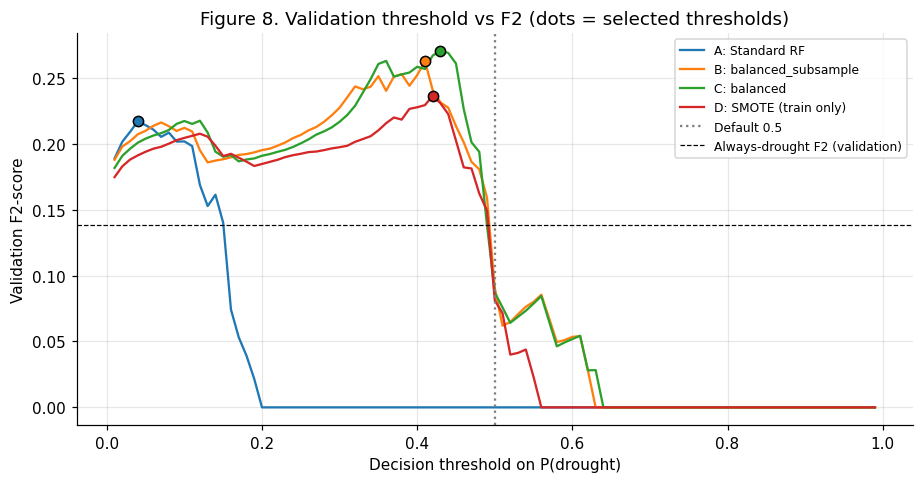

In [ ]:
fig, ax = plt.subplots(figsize=(8.5, 4.5))
for i, (k, sw) in enumerate(SWEEPS.items()):
    c = f"C{i}"
    ax.plot(sw["threshold"], sw["f2"], color=c, label=EXPERIMENTS[k]["label"])
    ax.scatter([THRESH_INFO[k]["threshold"]], [THRESH_INFO[k]["val_f2"]], color=c, zorder=5, s=45, edgecolor="k")
ax.axvline(DEFAULT_THRESHOLD, color="grey", ls=":", label="Default 0.5")
ax.axhline(fbeta(y_val.mean(), 1.0, 2), color="k", ls="--", lw=0.8, label="Always-drought F2 (validation)")
ax.set(xlabel="Decision threshold on P(drought)", ylabel="Validation F2-score",
       title="Figure 8. Validation threshold vs F2 (dots = selected thresholds)")
ax.legend(fontsize=8); plt.tight_layout(); plt.savefig(OUT_DIR / "fig08_validation_threshold_f2.png", dpi=150); plt.show()

In [ ]:
FROZEN = {k: {"config": RESULTS[k]["cfg"], "threshold": THRESH_INFO[k]["threshold"], "threshold_rule": THRESH_INFO[k]["method"],
              "default_threshold": DEFAULT_THRESHOLD} for k in THRESH_INFO}
cands = {k: (RESULTS[k]["val_ap"] if np.isfinite(RESULTS[k]["val_ap"]) else -np.inf) for k in THRESH_INFO}
BEST_KEY = max(cands, key=lambda k: (cands[k], -list(EXPERIMENTS).index(k)))
FROZEN["_best_strategy_by_validation"] = BEST_KEY
FROZEN_HASH = hashlib.sha256(json.dumps(FROZEN, sort_keys=True, default=str).encode()).hexdigest()
print("Frozen decisions:"); print(json.dumps(FROZEN, indent=2, default=str))
print("SHA-256 of frozen decisions:", FROZEN_HASH)
check("no attempt to read the test set before freezing", TEST.blocked_attempts == 0)
TEST.unseal(FROZEN_HASH)

Frozen decisions:
{
  "A_standard": {
    "config": {
      "min_samples_leaf": 20,
      "max_depth": null
    },
    "threshold": 0.04,
    "threshold_rule": "f2_max_on_validation",
    "default_threshold": 0.5
  },
  "B_balanced_subsample": {
    "config": {
      "min_samples_leaf": 1,
      "max_depth": 10
    },
    "threshold": 0.41,
    "threshold_rule": "f2_max_on_validation",
    "default_threshold": 0.5
  },
  "C_balanced": {
    "config": {
      "min_samples_leaf": 5,
      "max_depth": 10
    },
    "threshold": 0.43,
    "threshold_rule": "f2_max_on_validation",
    "default_threshold": 0.5
  },
  "D_smote": {
    "config": {
      "min_samples_leaf": 1,
      "max_depth": 10
    },
    "threshold": 0.42,
    "threshold_rule": "f2_max_on_validation",
    "default_threshold": 0.5
  },
  "_best_strategy_by_validation": "C_balanced"
}
SHA-256 of frozen decisions: 6c5e0299b2350211bd3f58dc3c4d45bf8225b5fdeb83469e38393c5c9329b01a
  [PASS] no attempt to read the test set before

In [ ]:
X_test_f, y_test_f = TEST.X, TEST.y
TEST_PROBA, test_rows = {}, []
for k in THRESH_INFO:
    p = RESULTS[k]["model"].predict_proba(X_test_f)[:, 1]
    TEST_PROBA[k] = p
    for tname, thr in [("default 0.5", DEFAULT_THRESHOLD), ("validation-selected", THRESH_INFO[k]["threshold"])]:
        m = compute_metrics(y_test_f, (p >= thr).astype(int), p)
        test_rows.append({"strategy": EXPERIMENTS[k]["label"], "threshold_type": tname, "threshold": thr, **m})

for name, val in [("Baseline: always non-drought", 0), ("Reference: always drought", 1)]:
    pr = np.full(len(y_test_f), val)
    test_rows.append({"strategy": name, "threshold_type": "n/a", "threshold": np.nan, **compute_metrics(y_test_f, pr, pr.astype(float))})
TEST_TABLE = pd.DataFrame(test_rows)
TEST_TABLE["pr_auc_minus_prevalence"] = TEST_TABLE["pr_auc_avg_precision"] - TEST_TABLE["prevalence"]
TEST_TABLE["pr_auc_over_prevalence"] = TEST_TABLE["pr_auc_avg_precision"] / TEST_TABLE["prevalence"]


FROZEN_AFTER = {k: {"config": RESULTS[k]["cfg"], "threshold": THRESH_INFO[k]["threshold"], "threshold_rule": THRESH_INFO[k]["method"],
                    "default_threshold": DEFAULT_THRESHOLD} for k in THRESH_INFO}
FROZEN_AFTER["_best_strategy_by_validation"] = BEST_KEY
check("frozen model/threshold decisions are byte-identical after test evaluation (no test result influenced selection)",
      hashlib.sha256(json.dumps(FROZEN_AFTER, sort_keys=True, default=str).encode()).hexdigest() == TEST.frozen_hash_at_unseal == FROZEN_HASH)

TEST_PREV = float(np.mean(y_test_f))
print(f"TEST SET: n = {len(y_test_f):,} | drought = {int(y_test_f.sum())} | non-drought = {int((y_test_f == 0).sum())} | natural drought prevalence = {TEST_PREV:.4f}")
main_cols = ["strategy", "threshold_type", "threshold", "accuracy", "precision_drought", "recall_drought", "f1", "f2", "specificity",
             "balanced_accuracy", "roc_auc", "pr_auc_avg_precision", "mcc", "TN", "FP", "FN", "TP"]
display(TEST_TABLE[main_cols].round(4))
print("\nPR-AUC (average precision) compared with the no-skill prevalence baseline:")
display(TEST_TABLE[TEST_TABLE["threshold_type"].isin(["default 0.5", "n/a"])][["strategy", "pr_auc_avg_precision", "prevalence",
      "pr_auc_minus_prevalence", "pr_auc_over_prevalence"]].round(4))

  [PASS] frozen model/threshold decisions are byte-identical after test evaluation (no test result influenced selection)
TEST SET: n = 1,889 | drought = 32 | non-drought = 1857 | natural drought prevalence = 0.0169


,strategy,threshold_type,threshold,accuracy,precision_drought,recall_drought,f1,f2,specificity,balanced_accuracy,roc_auc,pr_auc_avg_precision,mcc,TN,FP,FN,TP
0,A: Standard RF,default 0.5,0.50,0.9831,0.0000,0.0000,0.0000,0.0000,1.0000,0.5000,0.8080,0.0417,0.0000,1857,0,32,0
1,A: Standard RF,validation-selected,0.04,0.4743,0.0303,0.9688,0.0588,0.1347,0.4658,0.7173,0.8080,0.0417,0.1125,865,992,1,31
2,B: balanced_subsample,default 0.5,0.50,0.9074,0.0559,0.2812,0.0933,0.1557,0.9181,0.5997,0.8783,0.0676,0.0922,1705,152,23,9
3,B: balanced_subsample,validation-selected,0.41,0.8354,0.0785,0.8125,0.1433,0.2832,0.8358,0.8241,0.8783,0.0676,0.2201,1552,305,6,26
4,C: balanced,default 0.5,0.50,0.8984,0.0604,0.3438,0.1028,0.1774,0.9079,0.6258,0.8755,0.0685,0.1101,1686,171,21,11
5,C: balanced,validation-selected,0.43,0.8444,0.0774,0.7500,0.1404,0.2740,0.8460,0.7980,0.8755,0.0685,0.2077,1571,286,8,24
6,D: SMOTE (train only),default 0.5,0.50,0.8322,0.0418,0.4062,0.0758,0.1481,0.8395,0.6229,0.7683,0.0358,0.0855,1559,298,19,13
7,D: SMOTE (train only),validation-selected,0.42,0.6776,0.0399,0.7812,0.0759,0.1656,0.6758,0.7285,0.7683,0.0358,0.1253,1255,602,7,25
8,Baseline: always non-drought,n/a,NaN,0.9831,0.0000,0.0000,0.0000,0.0000,1.0000,0.5000,0.5000,0.0169,0.0000,1857,0,32,0
9,Reference: always drought,n/a,NaN,0.0169,0.0169,1.0000,0.0333,0.0793,0.0000,0.5000,0.5000,0.0169,0.0000,0,1857,0,32



PR-AUC (average precision) compared with the no-skill prevalence baseline:


,strategy,pr_auc_avg_precision,prevalence,pr_auc_minus_prevalence,pr_auc_over_prevalence
0,A: Standard RF,0.0417,0.0169,0.0248,2.4617
2,B: balanced_subsample,0.0676,0.0169,0.0507,3.9904
4,C: balanced,0.0685,0.0169,0.0516,4.0463
6,D: SMOTE (train only),0.0358,0.0169,0.0189,2.1133
8,Baseline: always non-drought,0.0169,0.0169,0.0000,1.0000
9,Reference: always drought,0.0169,0.0169,0.0000,1.0000


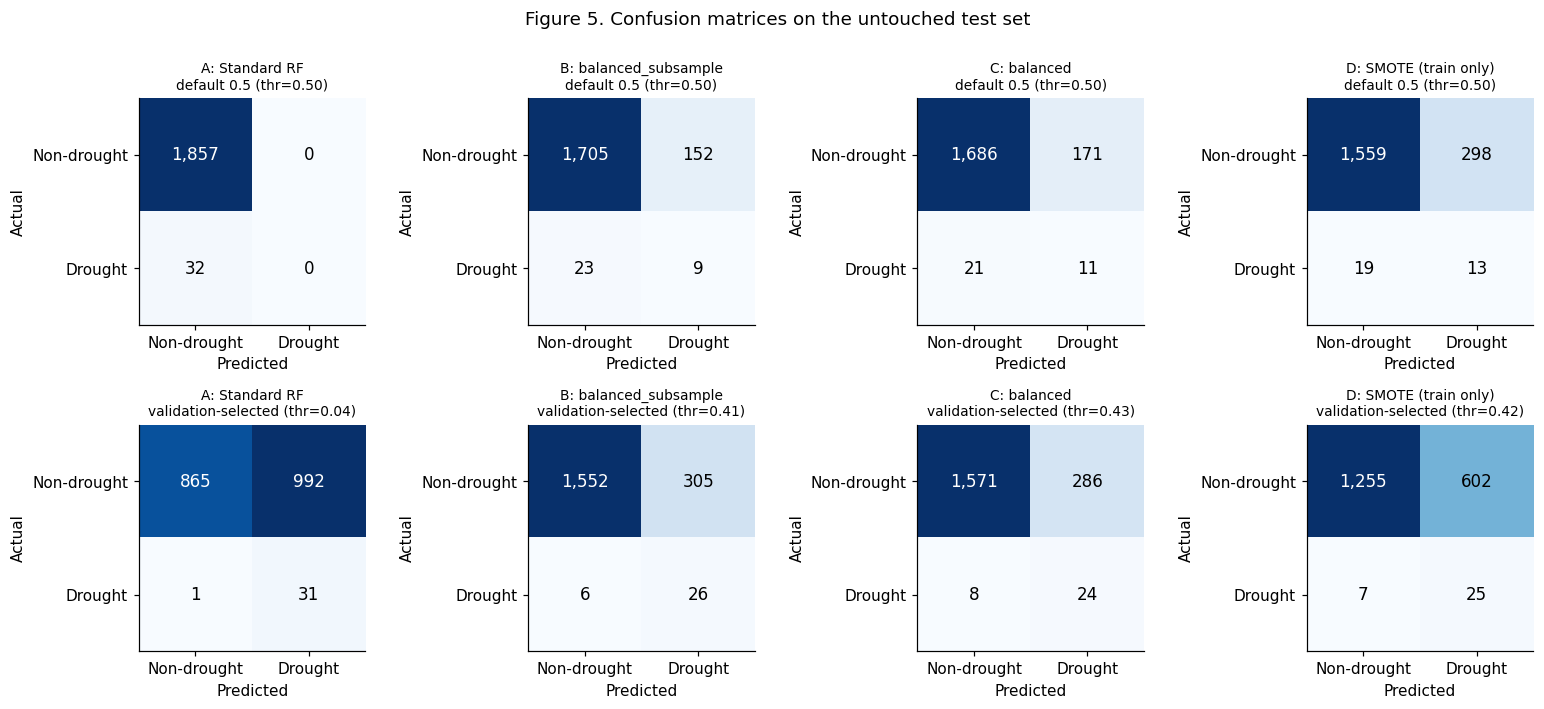

In [ ]:
STRAT_KEYS = list(THRESH_INFO)
fig, axes = plt.subplots(2, len(STRAT_KEYS), figsize=(3.6 * len(STRAT_KEYS), 6.4), squeeze=False)
for j, k in enumerate(STRAT_KEYS):
    for i, tname in enumerate(["default 0.5", "validation-selected"]):
        r = TEST_TABLE[(TEST_TABLE["strategy"] == EXPERIMENTS[k]["label"]) & (TEST_TABLE["threshold_type"] == tname)].iloc[0]
        cm = np.array([[r["TN"], r["FP"]], [r["FN"], r["TP"]]])
        ax = axes[i, j]; ax.imshow(cm, cmap="Blues"); ax.grid(False)
        for a in range(2):
            for b in range(2):
                ax.text(b, a, f"{cm[a, b]:,}", ha="center", va="center", color="white" if cm[a, b] > cm.max() / 2 else "black", fontsize=11)
        ax.set_xticks([0, 1]); ax.set_xticklabels(["Non-drought", "Drought"]); ax.set_yticks([0, 1]); ax.set_yticklabels(["Non-drought", "Drought"])
        ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
        ax.set_title(f"{EXPERIMENTS[k]['label']}\n{tname} (thr={r['threshold']:.2f})", fontsize=9)
fig.suptitle("Figure 5. Confusion matrices on the untouched test set", y=1.0)
plt.tight_layout(); plt.savefig(OUT_DIR / "fig05_confusion_matrices.png", dpi=150, bbox_inches="tight"); plt.show()

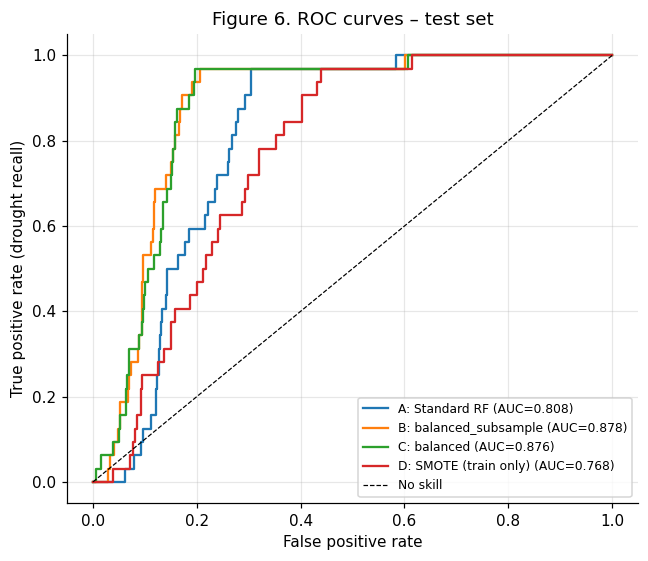

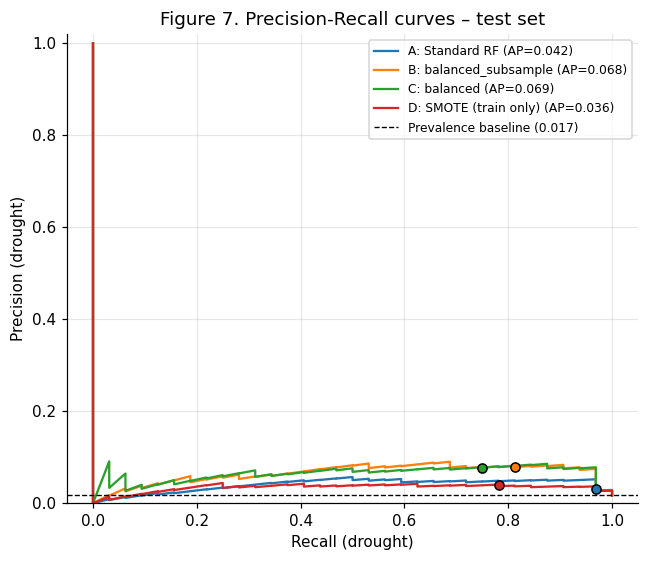

In [ ]:
has_both = 0 < y_test_f.sum() < len(y_test_f)
fig, ax = plt.subplots(figsize=(6, 5.2))
if has_both:
    for i, k in enumerate(STRAT_KEYS):
        fpr, tpr, _ = roc_curve(y_test_f, TEST_PROBA[k]); auc = roc_auc_score(y_test_f, TEST_PROBA[k])
        ax.plot(fpr, tpr, color=f"C{i}", label=f"{EXPERIMENTS[k]['label']} (AUC={auc:.3f})")
else:
    ax.text(0.5, 0.5, "Test set has a single class:\nROC undefined", ha="center")
ax.plot([0, 1], [0, 1], "k--", lw=0.8, label="No skill")
ax.set(xlabel="False positive rate", ylabel="True positive rate (drought recall)", title="Figure 6. ROC curves – test set")
ax.legend(fontsize=8, loc="lower right"); plt.tight_layout(); plt.savefig(OUT_DIR / "fig06_roc_test.png", dpi=150); plt.show()

fig, ax = plt.subplots(figsize=(6, 5.2))
if y_test_f.sum() > 0:
    for i, k in enumerate(STRAT_KEYS):
        pr_, rc_, _ = precision_recall_curve(y_test_f, TEST_PROBA[k]); ap = average_precision_score(y_test_f, TEST_PROBA[k])
        ax.plot(rc_, pr_, color=f"C{i}", label=f"{EXPERIMENTS[k]['label']} (AP={ap:.3f})")
        r = TEST_TABLE[(TEST_TABLE["strategy"] == EXPERIMENTS[k]["label"]) & (TEST_TABLE["threshold_type"] == "validation-selected")].iloc[0]
        ax.scatter([r["recall_drought"]], [r["precision_drought"]], color=f"C{i}", edgecolor="k", zorder=5)
ax.axhline(TEST_PREV, color="k", ls="--", lw=0.9, label=f"Prevalence baseline ({TEST_PREV:.3f})")
ax.set(xlabel="Recall (drought)", ylabel="Precision (drought)", ylim=(0, 1.02), title="Figure 7. Precision-Recall curves – test set")
ax.legend(fontsize=8); plt.tight_layout(); plt.savefig(OUT_DIR / "fig07_pr_test.png", dpi=150); plt.show()

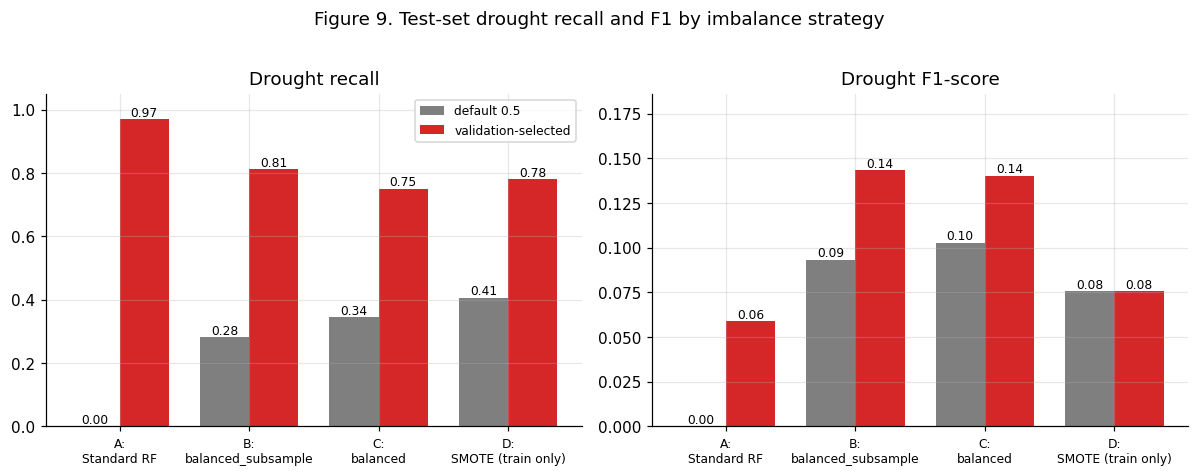

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
labels = [EXPERIMENTS[k]["label"] for k in STRAT_KEYS]; x = np.arange(len(labels)); w = 0.38
for ax, col, title in [(axes[0], "recall_drought", "Drought recall"), (axes[1], "f1", "Drought F1-score")]:
    for off, tname, colr in [(-w/2, "default 0.5", "tab:grey"), (w/2, "validation-selected", "tab:red")]:
        vals = [TEST_TABLE[(TEST_TABLE["strategy"] == l) & (TEST_TABLE["threshold_type"] == tname)][col].iloc[0] for l in labels]
        bars = ax.bar(x + off, vals, w, label=tname, color=colr)
        for b, v in zip(bars, vals):
            ax.text(b.get_x() + b.get_width()/2, (0 if not np.isfinite(v) else v), f"{v:.2f}", ha="center", va="bottom", fontsize=8)
    ymax = 1.05 if col == "recall_drought" else max(0.1, 1.3 * np.nanmax([b.get_height() for b in ax.patches]))
    ax.set_xticks(x); ax.set_xticklabels([l.replace(": ", ":\n") for l in labels], fontsize=8); ax.set_ylim(0, ymax); ax.set_title(title)
axes[0].legend(fontsize=8)
fig.suptitle("Figure 9. Test-set drought recall and F1 by imbalance strategy", y=1.02)
plt.tight_layout(); plt.savefig(OUT_DIR / "fig09_recall_f1_comparison.png", dpi=150, bbox_inches="tight"); plt.show()

Model analysed: C: balanced {'min_samples_leaf': 5, 'max_depth': 10}


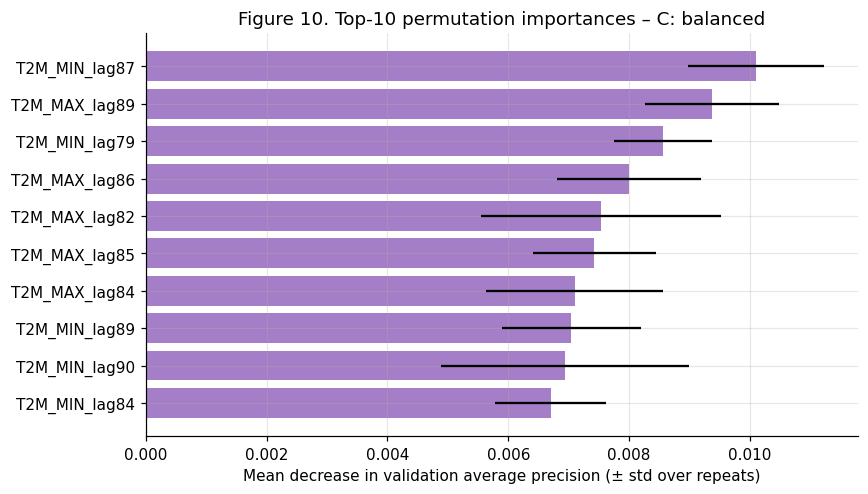

,feature,perm_importance_mean,perm_importance_std,impurity_importance
266,T2M_MIN_lag87,0.01010,0.00113,0.01706
178,T2M_MAX_lag89,0.00938,0.00110,0.02370
258,T2M_MIN_lag79,0.00856,0.00081,0.01127
175,T2M_MAX_lag86,0.00800,0.00120,0.01619
171,T2M_MAX_lag82,0.00753,0.00199,0.01251
174,T2M_MAX_lag85,0.00743,0.00101,0.01700
173,T2M_MAX_lag84,0.00710,0.00146,0.01677
268,T2M_MIN_lag89,0.00704,0.00115,0.01482
269,T2M_MIN_lag90,0.00694,0.00206,0.02110
263,T2M_MIN_lag84,0.00671,0.00092,0.00844


In [ ]:
best_model = RESULTS[BEST_KEY]["model"]
print("Model analysed:", EXPERIMENTS[BEST_KEY]["label"], RESULTS[BEST_KEY]["cfg"])
if y_val.sum() > 0:
    pi = permutation_importance(best_model, X_val, y_val, scoring="average_precision", n_repeats=PERM_REPEATS,
                                random_state=SEED, n_jobs=1)
    IMPORTANCE = pd.DataFrame({"feature": FEATURES, "perm_importance_mean": pi.importances_mean,
                               "perm_importance_std": pi.importances_std,
                               "impurity_importance": best_model.feature_importances_}).sort_values("perm_importance_mean", ascending=False)
    top10 = IMPORTANCE.head(10).iloc[::-1]
    fig, ax = plt.subplots(figsize=(8, 4.6))
    ax.barh(top10["feature"], top10["perm_importance_mean"], xerr=top10["perm_importance_std"], color="tab:purple", alpha=0.85)
    ax.set(xlabel="Mean decrease in validation average precision (± std over repeats)",
           title=f"Figure 10. Top-10 permutation importances – {EXPERIMENTS[BEST_KEY]['label']}")
    plt.tight_layout(); plt.savefig(OUT_DIR / "fig10_top10_permutation_importance.png", dpi=150); plt.show()
    display(IMPORTANCE.head(10).round(5))
else:
    IMPORTANCE = pd.DataFrame(); print("Validation set contains no drought samples: permutation importance (average precision) is undefined; skipped.")

In [ ]:
month_rate = y_train.groupby(X_train.index.month).mean()
overall = float(y_train.mean())
season_score = lambda idx: np.array([month_rate.get(m, overall) for m in idx.month], dtype=float)
sv, st = season_score(X_val.index), season_score(TEST.dates)
thr_s, sw_s, how_s = select_threshold(y_val, sv)
rows = []
for tname, thr in [("default 0.5", DEFAULT_THRESHOLD), ("validation-selected", thr_s)]:
    rows.append({"strategy": "Seasonal-frequency reference (month of t only)", "threshold_type": tname, "threshold": thr,
                 **compute_metrics(y_test_f, (st >= thr).astype(int), st)})
SEASONAL_TABLE = pd.DataFrame(rows)
display(SEASONAL_TABLE[main_cols].round(4))

mon = pd.DataFrame({"train": y_train.groupby(X_train.index.month).mean(), "validation": y_val.groupby(X_val.index.month).mean(),
                    "test": pd.Series(y_test_f.to_numpy(), index=TEST.dates).groupby(TEST.dates.month).mean()})
mon.index.name = "calendar month of prediction date t"
print("Drought-label frequency by calendar month of the prediction date, per partition:")
display(mon.round(3))

,strategy,threshold_type,threshold,accuracy,precision_drought,recall_drought,f1,f2,specificity,balanced_accuracy,roc_auc,pr_auc_avg_precision,mcc,TN,FP,FN,TP
0,Seasonal-frequency reference (month of t only),default 0.5,0.50,0.9831,0.0000,0.0000,0.0000,0.0000,1.0000,0.5000,0.8154,0.0584,0.0000,1857,0,32,0
1,Seasonal-frequency reference (month of t only),validation-selected,0.12,0.6977,0.0516,0.9688,0.0979,0.2126,0.6931,0.8309,0.8154,0.0584,0.1834,1287,570,1,31


Drought-label frequency by calendar month of the prediction date, per partition:


,train,validation,test
calendar month of prediction date t,,,
1,0.004,0.000,0.000
2,0.141,0.000,0.028
3,0.087,0.000,0.000
4,0.096,0.025,0.000
5,0.129,0.113,0.000
6,0.129,0.150,0.167
7,0.201,0.000,0.013
8,0.053,0.074,0.000
9,0.004,0.011,0.006


date,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,...,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
drought_share,0.027,0.159,0.036,0.09,0.098,0.016,0.055,0.033,0.104,0.074,...,0.153,0.049,0.022,0.038,0.016,0.085,0.0,0.0,0.0,0.0
drought_days,10.000,58.000,13.000,33.00,36.000,6.000,20.000,12.000,38.000,27.000,...,56.000,18.000,8.000,14.000,6.000,31.000,0.0,0.0,0.0,0.0
n_days,366.000,365.000,365.000,365.00,366.000,365.000,365.000,365.000,366.000,365.000,...,366.000,365.000,365.000,365.000,366.000,365.000,365.0,365.0,366.0,306.0


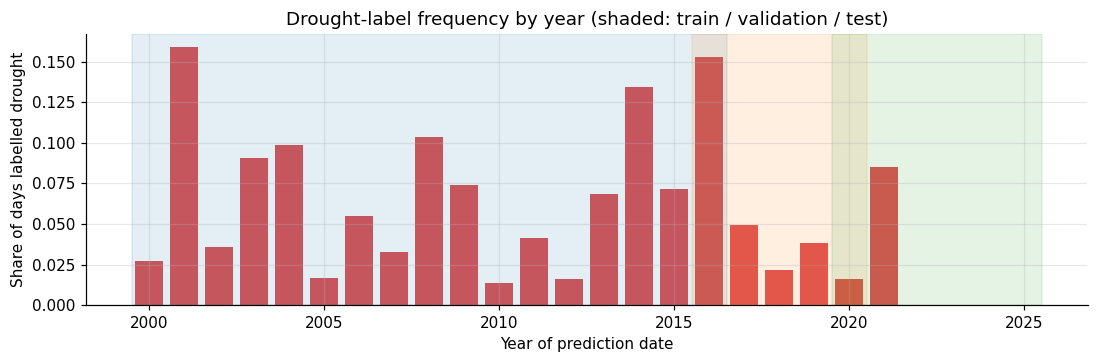

In [ ]:
yr = y_all.groupby(y_all.index.year).agg(["mean", "sum", "count"]).rename(columns={"mean": "drought_share", "sum": "drought_days", "count": "n_days"})
display(yr.round(3).T)
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.bar(yr.index, yr["drought_share"], color="tab:red", alpha=0.8)
for lo, hi, c in [(X_train.index.min(), X_train.index.max(), "tab:blue"), (X_val.index.min(), X_val.index.max(), "tab:orange"), (TEST.dates.min(), TEST.dates.max(), "tab:green")]:
    ax.axvspan(lo.year - 0.5, hi.year + 0.5, color=c, alpha=0.12)
ax.set(xlabel="Year of prediction date", ylabel="Share of days labelled drought", title="Drought-label frequency by year (shaded: train / validation / test)")
plt.tight_layout(); plt.savefig(OUT_DIR / "figS1_drought_share_by_year.png", dpi=150); plt.show()

In [ ]:
def row(k, tname): return TEST_TABLE[(TEST_TABLE["strategy"] == EXPERIMENTS[k]["label"]) & (TEST_TABLE["threshold_type"] == tname)].iloc[0]
print(f"Best strategy chosen on VALIDATION (highest validation average precision): {EXPERIMENTS[BEST_KEY]['label']}")
print(f"Test set: {len(y_test_f):,} days, {int(y_test_f.sum())} drought days in {PARTITION_TABLE.loc['Test','drought_episodes']} separate episode(s); "
      f"prevalence {TEST_PREV:.3%}; always-non-drought accuracy = {1 - TEST_PREV:.4f}.\n")
for k in STRAT_KEYS:
    d, s = row(k, "default 0.5"), row(k, "validation-selected")
    ap = d["pr_auc_avg_precision"]
    verdict_pr = "above" if ap > TEST_PREV else "NOT above"
    print(f"{EXPERIMENTS[k]['label']}:")
    print(f"   ROC-AUC={d['roc_auc']:.3f} | PR-AUC={ap:.3f} ({verdict_pr} the prevalence baseline {TEST_PREV:.3f})")
    print(f"   thr 0.5      -> recall={d['recall_drought']:.3f}, precision={d['precision_drought']:.3f}, F2={d['f2']:.3f}, MCC={d['mcc']:.3f} (TP={d['TP']}, FN={d['FN']}, FP={d['FP']})")
    print(f"   thr {s['threshold']:.2f} (val) -> recall={s['recall_drought']:.3f}, precision={s['precision_drought']:.3f}, F2={s['f2']:.3f}, MCC={s['mcc']:.3f} "
          f"(TP={s['TP']}, FN={s['FN']}, FP={s['FP']}; flags {s['predicted_drought_rate']:.1%} of test days)")
    if s["TP"] == 0 and d["TP"] == 0:
        print("   -> NO drought day detected at either threshold.")
none_detect = [EXPERIMENTS[k]["label"] for k in STRAT_KEYS if row(k, "default 0.5")["TP"] == 0 and row(k, "validation-selected")["TP"] == 0]
print("\nStrategies with zero true positives at both thresholds:", none_detect if none_detect else "none")
sea = SEASONAL_TABLE[SEASONAL_TABLE["threshold_type"] == "validation-selected"].iloc[0]
print(f"Seasonal-frequency reference (month only): ROC-AUC={sea['roc_auc']:.3f}, PR-AUC={sea['pr_auc_avg_precision']:.3f}, recall={sea['recall_drought']:.3f}, precision={sea['precision_drought']:.3f}")
better = [EXPERIMENTS[k]["label"] for k in STRAT_KEYS if row(k, "default 0.5")["pr_auc_avg_precision"] > sea["pr_auc_avg_precision"]]
print("RF strategies with higher test PR-AUC than the month-only reference:", better if better else "none")

Best strategy chosen on VALIDATION (highest validation average precision): C: balanced
Test set: 1,889 days, 32 drought days in 3 separate episode(s); prevalence 1.694%; always-non-drought accuracy = 0.9831.

A: Standard RF:
   ROC-AUC=0.808 | PR-AUC=0.042 (above the prevalence baseline 0.017)
   thr 0.5      -> recall=0.000, precision=0.000, F2=0.000, MCC=0.000 (TP=0, FN=32, FP=0)
   thr 0.04 (val) -> recall=0.969, precision=0.030, F2=0.135, MCC=0.113 (TP=31, FN=1, FP=992; flags 54.2% of test days)
B: balanced_subsample:
   ROC-AUC=0.878 | PR-AUC=0.068 (above the prevalence baseline 0.017)
   thr 0.5      -> recall=0.281, precision=0.056, F2=0.156, MCC=0.092 (TP=9, FN=23, FP=152)
   thr 0.41 (val) -> recall=0.812, precision=0.079, F2=0.283, MCC=0.220 (TP=26, FN=6, FP=305; flags 17.5% of test days)
C: balanced:
   ROC-AUC=0.876 | PR-AUC=0.069 (above the prevalence baseline 0.017)
   thr 0.5      -> recall=0.344, precision=0.060, F2=0.177, MCC=0.110 (TP=11, FN=21, FP=171)
   thr 0.43 (v

In [ ]:
CHECK_TABLE = pd.DataFrame(CHECKS)
pd.set_option("display.max_colwidth", 140)
display(CHECK_TABLE)
assert CHECK_TABLE["passed"].all(), "At least one leakage/integrity check failed."
print(f"\nAll {len(CHECK_TABLE)} integrity / leakage checks passed.")

,check,passed,detail
0,required columns present,True,[]
1,no duplicate dates,True,0 duplicates
2,daily series is continuous (no missing calendar days),True,0 missing days
3,no missing values after -999 -> NaN,True,"{'PRECTOTCORR': 0, 'T2M_MAX': 0, 'T2M_MIN': 0}"
4,precipitation is non-negative,True,
5,data cover the reference start,True,first date 1981-01-01
6,enough history before first prediction date for 90 lags,True,first date 1981-01-01
7,SPI parameters unchanged when ALL post-2010 precipitation is replaced with random values,True,
8,all SPI fitting windows end within 1981-2010,True,
9,no 2011-2025 observation (incl. 2021-2025 test years) enters SPI fitting,True,



All 37 integrity / leakage checks passed.


In [ ]:
def save(dfx, name, index=True):
    dfx.to_csv(OUT_DIR / name, index=index); print("saved", OUT_DIR / name)

save(SPI_TABLE.drop(columns=["ref_first_window_end", "ref_last_window_end"]), "spi_reference_parameters_1981_2010.csv")
save(PARTITION_TABLE, "partition_counts.csv")
save(SEARCH_TABLE, "hyperparameter_search_validation.csv", index=False)
save(VAL_SUMMARY, "validation_summary_and_thresholds.csv")
save(pd.concat([sw.assign(strategy=EXPERIMENTS[k]["label"]) for k, sw in SWEEPS.items()]), "validation_threshold_sweeps.csv", index=False)
save(TEST_TABLE, "test_metrics_all_strategies.csv", index=False)
save(SEASONAL_TABLE, "supplementary_seasonal_reference_test.csv", index=False)
save(mon, "drought_frequency_by_month_and_partition.csv")
if len(IMPORTANCE): save(IMPORTANCE, "permutation_importance_validation.csv", index=False)
pred_df = pd.DataFrame({"date": TEST.dates, "y_true": y_test_f.to_numpy()})
for k in STRAT_KEYS: pred_df[f"proba_{k}"] = TEST_PROBA[k]
save(pred_df, "test_predictions.csv", index=False)
save(CHECK_TABLE, "leakage_integrity_checks.csv", index=False)

meta_out = dict(research_title="Meteorological Drought Prediction Using Random Forest",
                data_file=os.path.basename(DATA_PATH), coordinates_lat_lon=[META.get("lat_meta"), META.get("lon_meta")],
                time_standard=META.get("time_standard"), data_range=[str(df.index.min().date()), str(df.index.max().date())],
                spi=dict(window=SPI_WINDOW, threshold=SPI_THRESHOLD, reference=[str(REF_START.date()), str(REF_END.date())]),
                prediction=dict(max_lag=MAX_LAG, horizon_days=HORIZON, n_features=len(FEATURES), purge_days=PURGE_DAYS),
                split=dict(train=[str(X_train.index.min().date()), str(X_train.index.max().date())],
                           validation=[str(X_val.index.min().date()), str(X_val.index.max().date())],
                           test=[str(TEST.dates.min().date()), str(TEST.dates.max().date())]),
                seed=SEED, n_estimators=N_ESTIMATORS, quick_mode=QUICK_MODE, frozen_decisions=FROZEN, frozen_hash=FROZEN_HASH,
                best_strategy_by_validation=BEST_KEY,
                versions=dict(python=platform.python_version(), numpy=np.__version__, pandas=pd.__version__,
                              scipy=scipy.__version__, sklearn=sklearn.__version__))
with open(OUT_DIR / "run_metadata.json", "w") as fh:
    json.dump(meta_out, fh, indent=2, default=str)


bundle = dict(model=RESULTS[BEST_KEY]["model"], strategy=EXPERIMENTS[BEST_KEY]["label"], threshold=THRESH_INFO[BEST_KEY]["threshold"],
              default_threshold=DEFAULT_THRESHOLD, features=FEATURES, spi_parameters={m: {k: v for k, v in p.items()} for m, p in SPI_PARAMS.items()},
              spi_reference=[str(REF_START.date()), str(REF_END.date())])
model_path = OUT_DIR / f"final_random_forest_{BEST_KEY}.joblib"
joblib.dump(bundle, model_path, compress=3)
print(f"saved {model_path}  ({model_path.stat().st_size / 1e6:.1f} MB)")

import shutil

zip_path = shutil.make_archive("drought_outputs", "zip", OUT_DIR)
print("Everything zipped to", zip_path)


try:
    from google.colab import files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False


if IN_COLAB:
    files.download(zip_path)
else:
    print("Download ZIP from:", os.path.abspath(zip_path))

saved drought_outputs/spi_reference_parameters_1981_2010.csv
saved drought_outputs/partition_counts.csv
saved drought_outputs/hyperparameter_search_validation.csv
saved drought_outputs/validation_summary_and_thresholds.csv
saved drought_outputs/validation_threshold_sweeps.csv
saved drought_outputs/test_metrics_all_strategies.csv
saved drought_outputs/supplementary_seasonal_reference_test.csv
saved drought_outputs/drought_frequency_by_month_and_partition.csv
saved drought_outputs/permutation_importance_validation.csv
saved drought_outputs/test_predictions.csv
saved drought_outputs/leakage_integrity_checks.csv
saved drought_outputs/final_random_forest_C_balanced.joblib  (1.4 MB)
Everything zipped to /content/drought_outputs.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>